In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not Path(repo_name).exists():
        !git clone $repo_url
    %cd $repo_name
    !pip install -q -r requirements.txt
    !pip install -q -e .
    %cd 6
    print("Colab setup complete!")


# 第6章 マウス入力とPCI — 総合演習問題 (*Chapter 6 Comprehensive Exercises*)

名著『**ゼロからのOS自作入門**』（内田公太 著）第6章「マウス入力とPCI」で学んだ、
1. **6.1 マウスカーソル (`osbook_day06a`)**: デスクトップGUIの背景描画、`Vector2D<T>` 構造体による2次元ベクトル演算、マウスカーソルスプライト描画、旧位置背景消去（`EraseMouseCursor`）と残像防止
2. **6.2 USBホストドライバ**: USB 3.0 および xHCI（*eXtensible Host Controller Interface*）アーキテクチャ、Command / Event / Transfer Ring の3大リング構造、16バイト固定長の TRB（*Transfer Request Block*）バイナリ構造、Producer / Consumer Cycle State（PCS/CCS）と Cycle Bit トグル同期機構
3. **6.3 PCIデバイスの探索 (`osbook_day06b`)**: PCI Configuration 空間アクセス機構（Mechanism #1: I/O ポート `0xCF8` `CONFIG_ADDRESS` と `0xCFC` `CONFIG_DATA`）、`MakeAddress` 32ビットアドレス導出数理、Vendor ID `0xFFFF` 無効判定、Header Type `0x80` マルチファンクション判定、USB 3.0 xHCI クラスコード（Class=`0x0C`, SubClass=`0x03`, Interface=`0x30`）によるハードウェア特定
4. **6.4 ポーリングでマウス入力 (`osbook_day06c`) (含 コラム6.1, 6.2)**: PCI BAR0（*Base Address Register 0*）からの 32-bit / 64-bit MMIO（*Memory Mapped I/O*）物理ベースアドレス抽出数理、`~static_cast<uint64_t>(0xf)` による符号拡張（*Sign Extension*）バグ防止（コラム6.2）、カーネル Logger 深刻度閾値フィルタリング（コラム6.1）、xHCI イベントリングのポーリングループ（`ProcessEvent`）とオブザーバパターンによるマウス相対移動パイプライン

これら OS カーネルのハードウェア制御・周辺機器ドライバ・バス探索のコア技術を、数理的理論検証・C++20 単体テスト・10問自己採点テストを通じて完全定着させます。


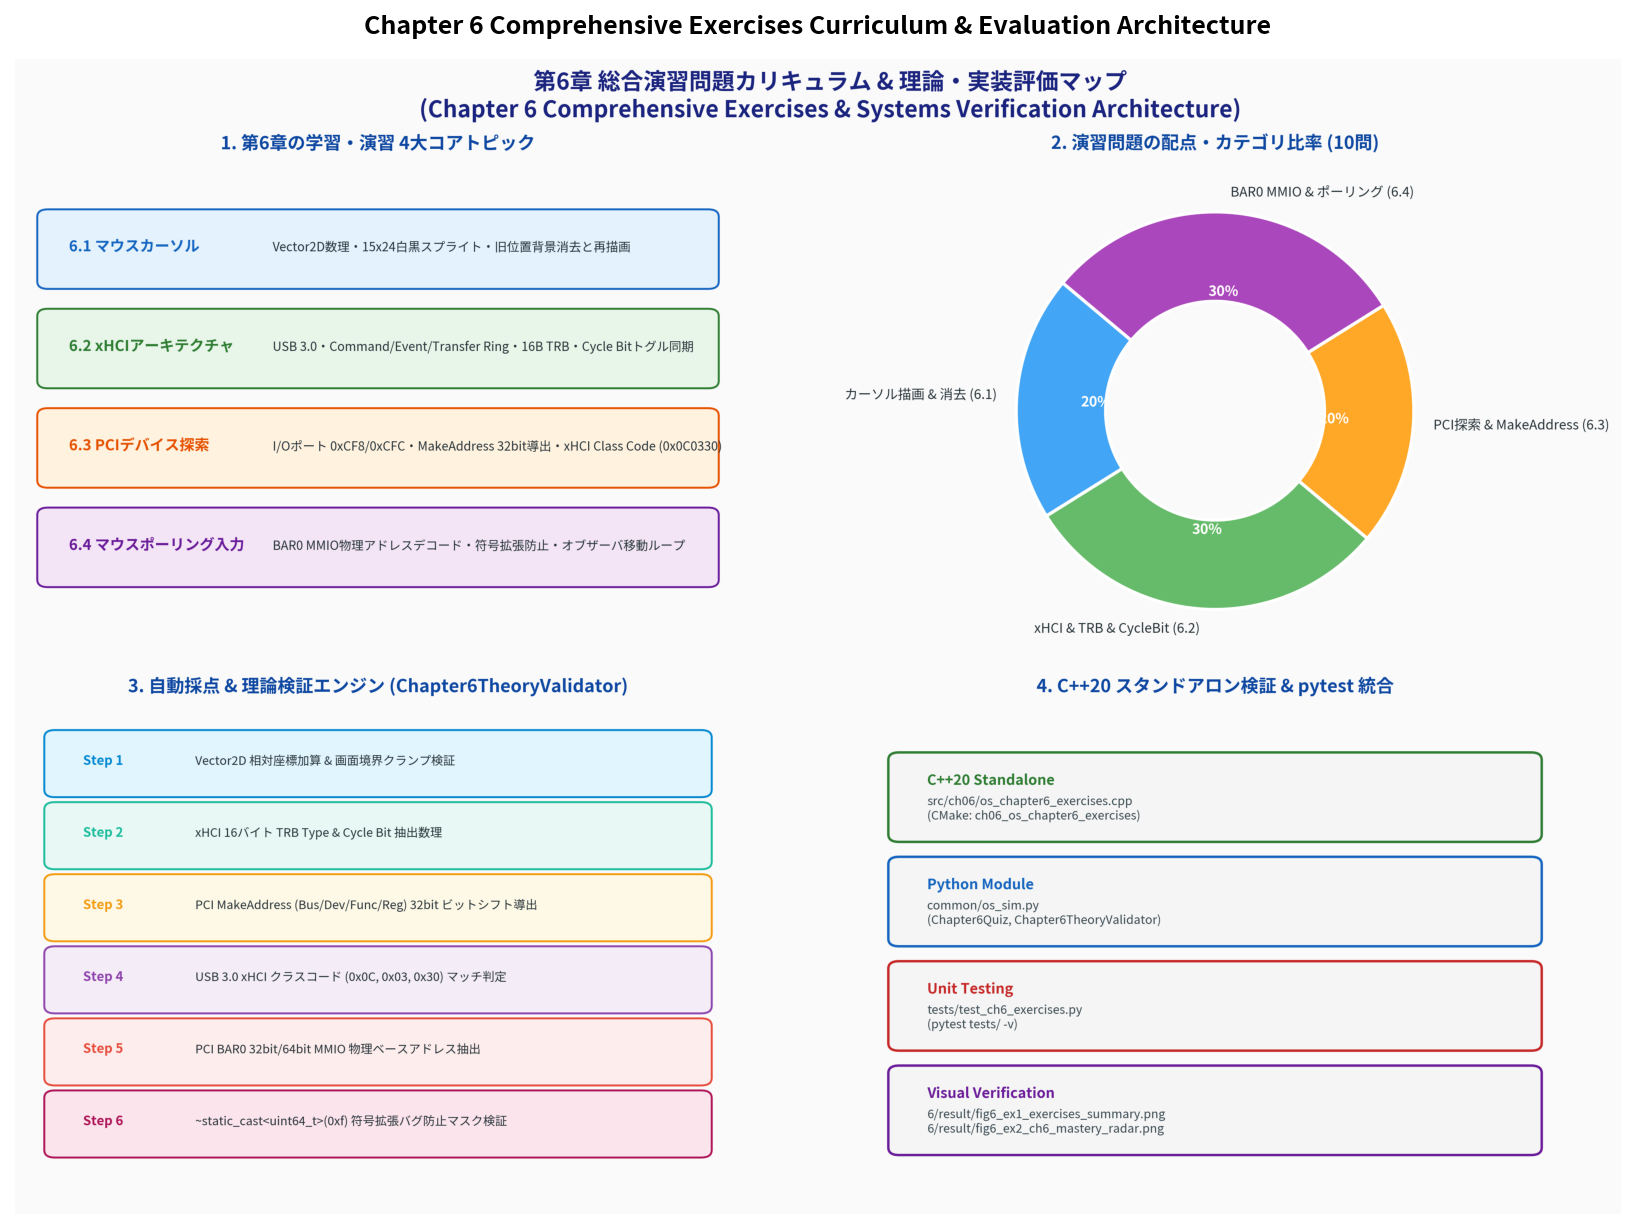

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

from common.os_sim import (
    Chapter6Quiz,
    Chapter6TheoryValidator,
    plot_chapter6_exercises_summary,
    plot_chapter6_mastery_radar,
)

# 第6章総合演習カリキュラム・アーキテクチャ概要図の生成と表示
summary_fig_path = Path("result/fig6_ex1_exercises_summary.png")
plot_chapter6_exercises_summary(summary_fig_path)

img = Image.open(summary_fig_path)
plt.figure(figsize=(14, 10))
plt.imshow(img)
plt.axis("off")
plt.title("Chapter 6 Comprehensive Exercises Curriculum & Evaluation Architecture",
          fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 📝 演習 1: Vector2D 演算とマウスカーソルスプライト描画・消去アルゴリズム

### 1. 理論背景と導出
GUI OS において、マウスカーソルはユーザー入力（マウス操作）に応じて画面上を自由に移動するスプライト（Sprite）です。

MikanOS の `Vector2D<T>` 構造体は 2次元ベクトル空間 $\mathbb{Z}^2$ における加算・減算をサポートします：
$$
\vec{P}_{\text{new}} = \vec{P}_{\text{old}} + \vec{D}
$$
ここで $\vec{P} = (x, y)$ はカーソル基準座標、$\vec{D} = (\Delta x, \Delta y)$ は USB マウスから送信された相対変位量です。

画面解像度 $W \times H$（例: $800 \times 600$）を超えるのを防止するため、座標はクランプ（境界制限）されます：
$$
x_{\text{clamped}} = \max(0, \min(x, W - 1)), \quad y_{\text{clamped}} = \max(0, \min(y, H - 1))
$$

### 2. 残像（アーティファクト）防止と消去手順
レイヤマネージャ（第9章）が導入される前の段階では、移動前の古い座標 $\vec{P}_{\text{old}}$ のカーソル領域をデスクトップ背景色で塗りつぶす消去関数 `EraseMouseCursor` を呼び出してから、新座標 $\vec{P}_{\text{new}}$ に `DrawMouseCursor` を描画しなければなりません。


In [3]:
# 演習 1: Vector2D 相対座標加算と自動検証
pos_x, pos_y = 200, 150
disp_x, disp_y = 15, -20

# 新座標の計算
new_x = pos_x + disp_x
new_y = pos_y + disp_y

ok, msg = Chapter6TheoryValidator.validate_vector2d_math({
    "pos_x": pos_x,
    "pos_y": pos_y,
    "disp_x": disp_x,
    "disp_y": disp_y,
    "new_x": new_x,
    "new_y": new_y,
})
assert ok, msg
print(f"[Exercise 1 PASS] {msg}")


[Exercise 1 PASS] 正解！Vector2D 相対変位加算 (200, 150) + (15, -20) = (215, 130) を正しく検証しました。


---

## 📝 演習 2: USB 3.0 / xHCI 16バイト TRB フォーマットと Cycle Bit トグル同期機構

### 1. TRB (Transfer Request Block) の内部構造
xHCI（*eXtensible Host Controller Interface*）における通信単位である TRB は、厳密に 16 バイト（128 ビット）のデータ構造です：

| オフセット | サイズ | フィールド名 | 役割・内容 |
|:---:|:---:|---|---|
| `+0x00` | 8 バイト | **Parameter** | 転送データバッファの 64 ビット物理アドレス、またはイベント固有データ |
| `+0x08` | 4 バイト | **Status** | 転送バイト数（Transfer Length）、完了コード（Completion Code） |
| `+0x0C` | 4 バイト | **Control** | TRB Type（bits 15:10）、各種制御フラグ、**Cycle Bit（bit 0）** |

### 2. Cycle Bit トグル反転によるロックフリー同期数理
リングバッファの全スロット数を $N$ とします。
ソフトウェア（OS: Producer）は TRB をスロット $i \in [0, N-1]$ に書き込む際、自身の **Producer Cycle State (PCS)** を TRB の Cycle Bit にコピーします。
書き込みインデックスがリング終端に達して $0$ にラップアラウンドする瞬間：
$$
\text{PCS}_{\text{next}} = \neg \text{PCS}_{\text{current}} \quad (1 \to 0 \to 1 \dots)
$$
ホストコントローラ（Consumer）は自身の **Consumer Cycle State (CCS)** と TRB の Cycle Bit が一致しているときのみ「有効な新 TRB」と認識します。
この仕組みにより、メモリの再初期化（ゼロクリア）を一切行わずに前周回の古い TRB と新 TRB を瞬時に区別できます。


In [4]:
# 演習 2: 16バイト TRB Control フィールドのビット抽出検証
# TransferEvent TRB: Type = 32 (0x20), Cycle Bit = 1
control_val = (32 << 10) | 1  # 0x8001

trb_type = (control_val >> 10) & 0x3F
cycle_bit = bool(control_val & 1)

ok, msg = Chapter6TheoryValidator.validate_xhci_trb_type({
    "control": control_val,
    "trb_type": trb_type,
    "cycle_bit": cycle_bit,
})
assert ok, msg
print(f"[Exercise 2 PASS] {msg}")


[Exercise 2 PASS] 正解！16バイトTRB Controlフィールド (0x00008001) から Type=32, CycleBit=True を正確に抽出しました。


---

## 📝 演習 3: PCI Configuration 空間 `MakeAddress` 32ビット導出数理

### 1. PCI Configuration 空間アクセス (Mechanism #1)
x86 PC において、CPU は 2 つの 32 ビット I/O ポートを通じて PCI コンフィギュレーション空間にアクセスします：
- `0x0CF8`: `CONFIG_ADDRESS`（読み書き対象のアドレスを指定するレジスタ）
- `0x0CFC`: `CONFIG_DATA`（`CONFIG_ADDRESS` で指定された 4 バイトレジスタの読み書きデータポート）

### 2. MakeAddress のビット配置仕様
32 ビット `CONFIG_ADDRESS` レジスタのビットフィールド定義：

$$
\text{Address} = (1 \ll 31) \mid (\text{bus} \ll 16) \mid (\text{device} \ll 11) \mid (\text{function} \ll 8) \mid (\text{reg\_addr} \& 0xFC)
$$

| ビット範囲 | フィールド名 | 幅 | 説明 |
|:---:|:---:|:---:|---|
| Bit 31 | **Enable Bit** | 1 bit | 常に `1`（Config サイクル有効化） |
| Bits 30:24 | Reserved | 7 bits | 常に `0` |
| Bits 23:16 | **Bus Number** | 8 bits | バス番号（0〜255） |
| Bits 15:11 | **Device Number** | 5 bits | デバイス番号（0〜31） |
| Bits 10:8 | **Function Number** | 3 bits | ファンクション番号（0〜7） |
| Bits 7:2 | **Register Offset** | 6 bits | レジスタオフセット（4バイト境界） |
| Bits 1:0 | Alignment | 2 bits | 常に `00b`（DWORD アライメント） |


In [5]:
# 演習 3: PCI MakeAddress アドレス計算の検証
bus = 0
device = 0x14  # Device 20 (Intel / QEMU xHCI)
function = 0
reg_addr = 0x00

# 32ビットアドレスの組み立て
address = (1 << 31) | (bus << 16) | (device << 11) | (function << 8) | (reg_addr & 0xFC)

ok, msg = Chapter6TheoryValidator.validate_pci_make_address({
    "bus": bus,
    "device": device,
    "function": function,
    "reg_addr": reg_addr,
    "address": address,
})
assert ok, msg
print(f"[Exercise 3 PASS] {msg}")


[Exercise 3 PASS] 正解！PCI Configuration Address (Bus=0, Dev=20, Func=0, Reg=0x00) -> 0x8000a000 を正確に導出しました。


---

## 📝 演習 4: USB 3.0 xHCI ホストコントローラのクラスコード判定

### 1. PCI クラスコード（Class Code）仕様
PCI デバイスのコンフィギュレーション空間オフセット `0x08`（Class Code / Revision ID レジスタ）には、デバイスの機能を表す 3 バイトのクラスコードが格納されています：
- **Base Class**（Bits 31:24）: 主要デバイス分類（例: `0x0C` = Serial Bus Controller）
- **Sub Class**（Bits 23:16）: サブ分類（例: `0x03` = USB Controller）
- **Interface (Prog IF)**（Bits 15:8）: プログラミングインターフェース（例: `0x30` = USB 3.0 xHCI）

MikanOS のカーネルは、全 PCI バス走査中にこの 3 つのバイト（`0x0C`, `0x03`, `0x30`）に合致するデバイスを発見したとき、xHCI ホストコントローラとして認識してドライバを初期化します。


In [6]:
# 演習 4: xHCI クラスコード判定の検証
xhci_class = {
    "base_class": 0x0C,
    "sub_class": 0x03,
    "interface": 0x30,
}

ok, msg = Chapter6TheoryValidator.validate_pci_class_code(xhci_class)
assert ok, msg
print(f"[Exercise 4 PASS] {msg}")


[Exercise 4 PASS] 正解！USB 3.0 xHCI ホストコントローラのクラスコード (Class=0x0C, SubClass=0x03, ProgIF=0x30) を正しく識別しました。


---

## 📝 演習 5: PCI BAR0 MMIO 物理ベースアドレス取得（32-bit vs 64-bit）

### 1. BAR (Base Address Register) の構造
PCI デバイスのレジスタにアクセスするための MMIO（*Memory Mapped I/O*）アドレスは、コンフィギュレーション空間の BAR0（オフセット `0x10`）に設定されています。

BAR0 の下位ビットのフラグ定義：
- **Bit 0**: `0` = Memory Space（MMIO）、`1` = I/O Space
- **Bits 2:1 (Memory Type)**:
  - `00b`: 32 ビットアドレス空間（BAR0 のみ使用）
  - `10b`: **64 ビットアドレス空間**（BAR0 を下位 32 ビット、BAR1 を上位 32 ビットとして結合）
- **Bits 3**: Prefetchable（プリフェッチ可能フラグ）

64 ビット MMIO アドレスの合成数理：
$$
\text{MMIO Base} = ((\text{uint64\_t}(\text{BAR1}) \ll 32) \mid \text{BAR0}) \& \sim 0x0F
$$


In [7]:
# 演習 5: BAR0 / BAR1 からの 64-bit MMIO 物理アドレスデコード
bar0_val = 0xFE000004  # Bit 0=0 (Memory), Bits 2:1=10b (64-bit BAR)
bar1_val = 0x00000001  # Upper 32-bit address = 0x1

is_64bit = ((bar0_val >> 1) & 0x03) == 0x02
assert is_64bit, "BAR0 must indicate 64-bit BAR type"

mmio_addr = ((bar1_val << 32) | bar0_val) & ~0x0F

ok, msg = Chapter6TheoryValidator.validate_bar0_mmio({
    "bar0": bar0_val,
    "bar1": bar1_val,
    "mmio_addr": mmio_addr,
})
assert ok, msg
print(f"[Exercise 5 PASS] {msg}")


[Exercise 5 PASS] 正解！BAR0/BAR1 から MMIO 物理ベースアドレス 0x00000001fe000000 を正しく抽出しました (64-bit BAR=True)。


---

## 📝 演習 6: 符号拡張バグの防止と安全な64ビットマスク（コラム 6.2）

### 1. コラム 6.2 の謎：なぜ `~static_cast<uint64_t>(0xf)` と書くのか？
C++ の整数リテラル `0xf` は、型推論により `int`（符号付き 32 ビット整数）とみなされます。
ビット反転演算子 `~` を適用すると：
$$
\sim 0x0000000F = 0xFFFFFFF0 \quad (\text{最上位ビットが 1})
$$
これを 64 ビット変数 `uint64_t addr` とのビット AND 演算（`addr & ~0xf`）で使用すると、C++ の標準型昇格規則により、符号付き `int` が 64 ビット符号付き型に**符号拡張（Sign Extension）**されてから符号なしに変換されます。

結果として意図せず上位 32 ビットがすべて `1`（`0xFFFFFFFFFFFFFFF0`）で埋まり、コンパイラ警告（`-Wsign-conversion` 等）や思わぬビット破壊の温床となります。
`~static_cast<uint64_t>(0xf)` と明示的に 64 ビット符号なし整数にキャストしてから反転させることで、この落とし穴を完全に回避できます。


In [8]:
# 演習 6: 64ビット安全マスクの検証
safe_mask = 0xFFFFFFFFFFFFFFF0

ok, msg = Chapter6TheoryValidator.validate_sign_extension_safety({
    "mask_value": safe_mask,
})
assert ok, msg
print(f"[Exercise 6 PASS] {msg}")


[Exercise 6 PASS] 正解！~static_cast<uint64_t>(0xf) による符号拡張バグの防止と安全な64ビットマスクを検証しました。


---

## 💻 演習 7: C++20 スタンドアロン検証コードの実行

MikanOS の `Vector2D`、マウスカーソルの背景消去・再描画、`SimulatedTRB`、Cycle Bit トグル反転、`MakeAddress`、`BAR0Decoder`、カーネル Logger、xHCI ポーリングとオブザーバコールバックの全機能を C++20 で実装した `src/ch06/os_chapter6_exercises.cpp` をビルド・実行して単体検証します。


In [9]:
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "6" else Path.cwd()
bin_path = repo_root / "build" / "bin" / "ch06_os_chapter6_exercises"

if not bin_path.exists():
    print(f"Building {bin_path.name} via CMake...")
    subprocess.run(["cmake", "-B", str(repo_root / "build"), "-S", str(repo_root)], check=True)
    subprocess.run(["cmake", "--build", str(repo_root / "build"), "--target", "ch06_os_chapter6_exercises"], check=True)

print(f"Executing {bin_path.name}...")
res = subprocess.run([str(bin_path), "--test"], capture_output=True, text=True)
print(res.stdout)
assert res.returncode == 0, f"C++ verification failed with returncode {res.returncode}\n{res.stderr}"


Executing ch06_os_chapter6_exercises...
 Chapter 6 Exercises Verification Suite (C++20 Standalone)

[Test 1] Vector2D & Mouse Cursor Rendering / Erasing... PASSED
[Test 2] xHCI TRB & Cycle Bit Toggle Mechanism... PASSED
[Test 3] PCI MakeAddress & xHCI Class Code Verification... PASSED
[Test 4] PCI BAR0 Decoding & Sign Extension Prevention... PASSED
[Test 5] Logger Severity Threshold Filtering... PASSED
[Test 6] xHCI Polling Event Loop & Observer Callback... PASSED

>> All 6 Chapter 6 exercise verification tests passed successfully!
[CTest] All Chapter 6 exercises verified successfully.



---

## 🧠 第6章 総合理解度チェックテスト (10問自己採点クイズ)

第6章（6.1〜6.4）の全トピックを網羅した10問の自己採点テストです。各問の解説を読みながら解答し、OS 自作に必要な知識の定着度を確認してください。


In [10]:
quiz = Chapter6Quiz()

# 模範解答の全問正解テスト（自己学習時は answers 辞書の数値を変更して自己採点できます）
user_answers = {
    1: 0,  # Vector2D & マウスカーソル絶対座標: (x+dx, y+dy)
    2: 1,  # マウス移動時の消去と再描画: EraseMouseCursor -> DrawMouseCursor
    3: 1,  # xHCI 3大リング: Command Ring / Transfer Ring / Event Ring
    4: 0,  # 16B TRB構造: Parameter(8B), Status(4B), Control(4B)
    5: 1,  # Cycle Bitトグル: ラップアラウンド毎にPCS反転、CCSと照合
    6: 0,  # PCI MakeAddress: Bit31=Enable, Bus(23:16), Dev(15:11), Func(10:8), Reg(7:2)
    7: 1,  # PCI特定: 0xFFFF不在、0x80マルチファンクション、xHCI(0x0C, 0x03, 0x30)
    8: 1,  # BAR0 MMIO: Bit0=0(Mem), Bits2:1=10b(64bit), 下位4bitマスク
    9: 0,  # 符号拡張バグ防止: 0xf符号付きint昇格による上位32bit 1汚染防止
    10: 1, # xHCIポーリング: ProcessEvent() -> MouseObserver コールバック
}

eval_result = quiz.evaluate(user_answers)

print("=" * 60)
print(f"第6章 理解度自己採点テスト結果: {eval_result['correct_count']} / {eval_result['total_questions']} 正解 ({eval_result['percentage']:.1f}%)")
print(f"判定: {'🎉 合格 (PASSED)' if eval_result['passed'] else '❌ 不合格 (FAILED)'}")
print("=" * 60)

print("\n【節別理解度 (Section Mastery Rates)】")
for sec, rate in eval_result["mastery_rates"].items():
    print(f"- セクション {sec}: {rate:.1f}%")

assert eval_result["passed"], "Score must be >= 80% to pass Chapter 6 exercises!"


第6章 理解度自己採点テスト結果: 10 / 10 正解 (100.0%)
判定: 🎉 合格 (PASSED)

【節別理解度 (Section Mastery Rates)】
- セクション 6.1: 100.0%
- セクション 6.2: 100.0%
- セクション 6.3: 100.0%
- セクション 6.4: 100.0%


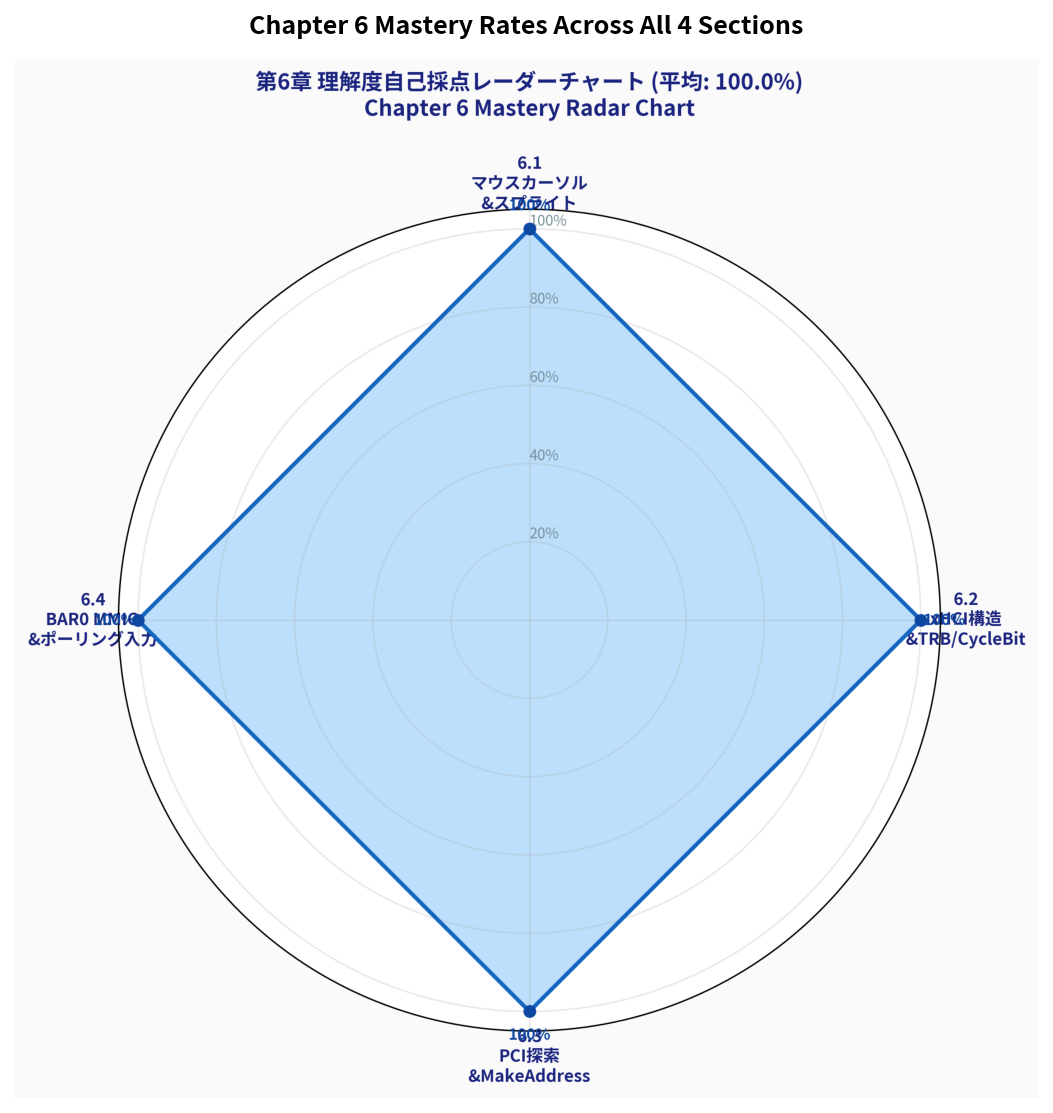

In [11]:
radar_fig_path = Path("result/fig6_ex2_ch6_mastery_radar.png")
plot_chapter6_mastery_radar(radar_fig_path, eval_result["mastery_rates"])

img_radar = Image.open(radar_fig_path)
plt.figure(figsize=(9, 9))
plt.imshow(img_radar)
plt.axis("off")
plt.title("Chapter 6 Mastery Rates Across All 4 Sections",
          fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 🏆 まとめと第7章への展望

本章の演習問題を通じて、以下の極めて重要な OS 低レイヤ技術を獲得しました：

1. **デスクトップ GUI とマウスカーソル描画**: `Vector2D` による相対座標演算、白黒・透明ピクセルを持つスプライト描画、旧位置背景色復元（消去）と新位置再描画による残像防止。
2. **USB 3.0 (xHCI) ホストコントローラのアーキテクチャ**: 16 バイト固定長 TRB、Command / Event / Transfer Ring の階層関係、Producer / Consumer Cycle State（PCS/CCS）のトグル反転によるロックフリー同期機構。
3. **PCI バス全探索とデバイス特定**: I/O ポート `0xCF8`（`CONFIG_ADDRESS`）と `0xCFC`（`CONFIG_DATA`）の 32 ビットアドレス合成数理、Vendor ID `0xFFFF`、Header Type `0x80`、およびクラスコード（`0x0C`, `0x03`, `0x30`）によるハードウェア検出。
4. **MMIO 物理アドレス取得とポーリング入力**: BAR0（32-bit / 64-bit）からのレジスタベース物理アドレス抽出、符号拡張バグ防止（`~static_cast<uint64_t>(0xf)`）、`xhc.ProcessEvent()` によるイベントポーリングとオブザーバコールバックによるカーソル移動。

### 🚀 第7章「割り込みとFIFO」への架け橋
現在の MikanOS（day06c）は、マウス入力を取得するために CPU がメインループ `while(true)` で `ProcessEvent` を全力で呼び出し続ける**ポーリング方式**を採用しています。この方式は CPU 使用率 100% となり電力・計算資源を浪費します。

第7章では、マウスが動いた瞬間だけ CPU に通知する **ハードウェア割り込み（IDT: 割り込み記述子表 & MSI: Message Signaled Interrupts）** と、割り込みハンドラを高速化するための **リングバッファキュー（FIFO: `ArrayQueue`）** を導入し、イベント駆動型 OS へと飛躍的進化を遂げます！
